# fibonacci_recoverability_kl
## 1. 研究目的
有限1次元Fibonacci-QECCについて、同じ消失集合 $E$ に対する古典的recoverabilityと量子KL条件を比較する。重点は**Type B（recoverability成功・KL失敗）**の発見と原因分解であり、Type Cも除外せず記録する。

このNotebookは同梱のPythonモジュール・既存資料snapshotと一緒に使用する。最初から順に実行する。既存結果との不一致、seed条件違反、テスト失敗があれば例外で停止する。巨大なstatevector・密度行列は使用しない。

## 2. 既存研究との関係
既存の `fibonacci_seed_variation` のseed一覧、設定、保存済みKL結果を読み取り、基本関数は既存Notebookから関数本体をそのまま抽出した `legacy_functions.py` を再利用する。元ファイルの場所とSHA256は `reference/provenance.json` に記録した。

元論文：Zhi Li・Latham Boyle, [The Penrose Tiling is a Quantum Error-Correcting Code, Appendix E](https://arxiv.org/html/2311.13040v2#A5)。有限巡回列の構成を参照し、本Notebookの具体的な隣接交換判定は依頼文および既存実装に合わせる。

**区別する量：**本研究の `recoverable_both` は各論理軌道を別々に見た一意復元性であり、論理ラベルが未知のときの $O_0\cup O_1$ 全体の一意復元性ではない。後者にはcross collisionがないことも必要になる。訂正率は消失配置のうち条件を満たす割合であり、回復回路を実行した物理的成功確率ではない。

## 3. パラメータ設定
既存候補の最初のpairを性能による選別なしに既定値とする。過去の任意消失解析と同じinflation 3回を用いる。`ERASURE_SIZES=None` は0〜Nすべて。`USE_MANUAL_SEEDS=True` でも同じ検証を行う。

サンプリングは全位置付きm部分集合から独立一様に復元抽出する。同じ集合が再出現した場合も別試行として保持し、`sample_index` で識別する。各mの乱数系列は呼出順に依存しない。

In [1]:
from pathlib import Path
import json
import sys
import pandas as pd
from IPython.display import display, Markdown
import recoverability_kl as fib

PROJECT_DIR = Path.cwd()
REFERENCE_DIR = PROJECT_DIR / "reference"
RESULTS_DIR = PROJECT_DIR / "results"
RESULTS_DIR.mkdir(exist_ok=True)

USE_MANUAL_SEEDS = False
SEED_0 = "000111"
SEED_1 = "010101"
PAIR_ID = "L06_W03_P0001"
LOGICAL_PAIR_FILE = REFERENCE_DIR / "seed_pairs.jsonl"
SEED_LENGTH, K0, K1 = 6, 3, 3  # 保存一覧がない場合だけ再生成に用いる
INFLATION_N = 3
ERASURE_SIZES = None
ENUMERATION_MODE = "auto"
MAX_EXACT_PATTERNS = 100000
NUM_RANDOM_SAMPLES = 10000
RANDOM_SEED = 42
BASELINE_VERIFIED = False


## 4. 既存コード・logical bitの確認
同梱snapshotのhashを確認し、過去の設定・一覧を表示する。既存の左から0始まりのindex、重複を除いた左巡回シフト、周期境界、等振幅正規化を引き継ぐ。過去の任意消失は回転代表と多重度で圧縮されているため、再現時はその重みを復元する。

一覧が存在すれば必ずその候補を使用する。再生成用の関数は提供するが、既定実行で一覧を勝手に作り直さない。別研究資料へ切り替える場合は、referenceの形式・出典・再現検証も整備する。

In [2]:
provenance = fib.verify_reference(REFERENCE_DIR)
old_config = json.loads((REFERENCE_DIR / "seed_variation_config.json").read_text())
pair_records = fib.load_jsonl(LOGICAL_PAIR_FILE) if LOGICAL_PAIR_FILE.exists() else []
print("既存研究:", provenance["source_project"])
print("既存seed対数:", len(pair_records))
print("旧seed条件:", old_config["seed_search"])
display(pd.DataFrame(pair_records).reindex(columns=["pair_id", "seed_a", "seed_b", "seed_length", "number_of_zeros", "number_of_ones"]).head(10))


既存研究: /Users/ideryuito/Documents/Codex/2026-07-27/jupyterlab-knill-laflamme-1-jupyter-notebook/outputs/fibonacci_seed_variation
既存seed対数: 89
旧seed条件: {'seed_lengths': [6, 7, 8, 9], 'max_seed_length': 9, 'number_of_ones_rule': 'floor_half', 'number_of_ones_overrides': {}, 'max_pairs_per_group': None, 'orthogonality_check_depths': [1, 2, 3, 4, 5], 'include_periodic_boundary_swap': True}


,pair_id,seed_a,seed_b,seed_length,number_of_zeros,number_of_ones
0,L06_W03_P0001,000111,010101,6,3,3
1,L07_W03_P0001,0000111,0010011,7,4,3
2,L07_W03_P0002,0000111,0010101,7,4,3
3,L08_W04_P0001,00001111,00011011,8,4,4
4,L08_W04_P0002,00001111,00100111,8,4,4
5,L08_W04_P0003,00001111,00101011,8,4,4
6,L08_W04_P0004,00001111,00101101,8,4,4
7,L08_W04_P0005,00001111,00110011,8,4,4
8,L08_W04_P0006,00001111,00110101,8,4,4
9,L08_W04_P0007,00001111,01010101,8,4,4


## 5. Fibonacci inflation
規則 `1 → 10, 0 → 1` を両seedに同じ回数適用する。`inflate(seed,n)` は既存関数へ規則を固定して渡す薄いwrapperである。

In [3]:
inflate = fib.inflate
print("10 →", inflate("10", 1), "→", inflate("10", 2))

10 → 101 → 10110


## 6. 巡回同値類
ringの全巡回シフトから重複を除く。周期的なseedでは軌道サイズがNより小さくなるため、正規化にはNではなく実際の軌道サイズを用いる。代表元は辞書順最小回転。

In [4]:
cyclic_orbit = fib.cyclic_orbit
canonical_rotation = fib.canonical_rotation
print(cyclic_orbit("010101"), canonical_rotation("101010"))

['010101', '101010'] 010101


## 7. 隣接交換条件
`01/10`の1回交換を末尾・先頭の境界も含めて調べる。異なる論理軌道の間に交換で移れる場合は除外する。両方向を検証する。

In [5]:
adjacent_swap_neighbors = fib.adjacent_swap_neighbors
satisfies_adjacent_swap_condition = fib.satisfies_adjacent_swap_condition
print("000111 の交換近傍:", adjacent_swap_neighbors("000111"))

000111 の交換近傍: ['001011', '100110']


## 8. valid logical pair確認
選択したpairに対し同じk0/k1、巡回非同値性、隣接交換条件を確認する。保存済み候補についても検証し、既存コードが確認していたinflation深さでの直交性を確認する。manual modeで不正な列を入力した場合はここで停止する。

In [6]:
generate_valid_logical_pairs = fib.generate_valid_logical_pairs
for r in pair_records:
    fib.validate_pair(r["seed_a"], r["seed_b"])
    for depth in r.get("orthogonality_check_depths", old_config["seed_search"]["orthogonality_check_depths"]):
        if canonical_rotation(inflate(r["seed_a"], depth)) == canonical_rotation(inflate(r["seed_b"], depth)):
            raise RuntimeError(f"保存候補のinflation後直交性が不成立: {r['pair_id']} n={depth}")
if USE_MANUAL_SEEDS:
    seed_0, seed_1 = SEED_0, SEED_1
elif pair_records:
    selected = [r for r in pair_records if r["pair_id"] == PAIR_ID]
    if len(selected) != 1:
        raise ValueError("PAIR_IDが既存一覧に一意に存在しません。")
    seed_0, seed_1 = selected[0]["seed_a"], selected[0]["seed_b"]
else:
    candidates = generate_valid_logical_pairs(SEED_LENGTH, K0, K1)
    if not candidates:
        raise ValueError("指定条件にvalid logical pairがありません。")
    seed_0, seed_1 = candidates[0]
pair_validation = fib.validate_pair(seed_0, seed_1)
print(seed_0, seed_1, pair_validation)

000111 010101 {'seed_length': 6, 'k0': 3, 'k1': 3, 'adjacent_swap_valid': True}


## 9. 既存研究結果の再現
snapshotに保存した `L06_W03_P0001`, inflation=3, N=24を共通の再現基準とする。任意消失m=1〜4は保存済み544回転代表を再計算し、旧集計CSVと重み付き訂正率を比較する。連続消失m=0〜15は全開始位置を確認する。

旧浮動小数KL実装と今回の整数判定を両方照合する。残差の定義は旧実装の $\frac12\|\rho_{00}-\rho_{11}\|_F$ と $\|\rho_{01}\|_F$ を保持する。判定または残差が一致しなければ原因を保存・表示して停止する。manualで別pairを選んだ場合も、この再現基準は共通に確認するが、そのpair自身の過去結果を再現したとは扱わない。

In [7]:
BASELINE_VERIFIED = False
baseline = fib.reproduce_baseline(REFERENCE_DIR, RESULTS_DIR)
if not baseline["matched"].all():
    raise RuntimeError("既存結果と不一致。新解析へ進めません。")
BASELINE_VERIFIED = True
display(baseline)
print("再現確認:", BASELINE_VERIFIED)

,kind,code_id,erasure_size,checked_representatives,weighted_trials,expected_success_rate,recomputed_success_rate,difference,matched
0,arbitrary,L06_W03_P0001_D03,1,1,24,1.000000,1.000000,0.000000e+00,True
1,arbitrary,L06_W03_P0001_D03,2,12,276,0.521739,0.521739,0.000000e+00,True
2,arbitrary,L06_W03_P0001_D03,3,85,2024,0.177866,0.177866,5.551115e-17,True
3,arbitrary,L06_W03_P0001_D03,4,446,10626,0.045172,0.045172,6.245005e-17,True
4,contiguous,L06_W03_P0001_D03,0,1,24,1.000000,1.000000,0.000000e+00,True
5,contiguous,L06_W03_P0001_D03,1,1,24,1.000000,1.000000,0.000000e+00,True
6,contiguous,L06_W03_P0001_D03,2,1,24,1.000000,1.000000,0.000000e+00,True
7,contiguous,L06_W03_P0001_D03,3,1,24,1.000000,1.000000,0.000000e+00,True
8,contiguous,L06_W03_P0001_D03,4,1,24,1.000000,1.000000,0.000000e+00,True
9,contiguous,L06_W03_P0001_D03,5,1,24,1.000000,1.000000,0.000000e+00,True


再現確認: True


## 10. 小さい系でunit test
群分けを使わない独立なbit列ペア総当たりの部分トレースと、整数kernelを照合する。N=9の全512消失集合、軌道サイズが異なる場合、空集合・全消失、ring境界、不正入力、Type Cの人工例、N>100の動作を含む。

人工Type Cは実装がCを除外しないことを調べるfixtureであり、Fibonacci族の発見ではない。

In [8]:
from test_recoverability_kl import run_tests
test_report = run_tests()
(RESULTS_DIR / "unit_test_report.json").write_text(json.dumps(test_report, indent=2))

test_analysis_gate (test_recoverability_kl.CoreTests.test_analysis_gate) ... 

ok


test_baseline_mismatch_stops (test_recoverability_kl.CoreTests.test_baseline_mismatch_stops) ... 

ok


test_generate_pairs (test_recoverability_kl.CoreTests.test_generate_pairs) ... 

ok


... (26 outputs left out)

test_unequal_normalization (test_recoverability_kl.CoreTests.test_unequal_normalization) ... 

ok


----------------------------------------------------------------------
Ran 17 tests in 0.164s

OK


53

## 11. logical orbit生成
$|i_L\rangle=|O_i|^{-1/2}\sum_{x\in O_i}|x\rangle$ を軌道集合のみで保持する。inflation後も同長かつ直交であることを確認する。高速計算にはPython整数を使用し、桁数を64bitへ制限しない。

In [9]:
if not BASELINE_VERIFIED:
    raise RuntimeError("先に既存結果を再現してください。")
model = fib.LogicalPair(seed_0, seed_1, INFLATION_N)
N, O0, O1 = model.N, model.O0, model.O1
print(json.dumps(model.metadata, ensure_ascii=False, indent=2))
print("inflated F0:", model.F0)
print("inflated F1:", model.F1)

{
  "seed_length": 6,
  "k0": 3,
  "k1": 3,
  "adjacent_swap_valid": true,
  "seed_0": "000111",
  "seed_1": "010101",
  "inflation_n": 3,
  "N": 24,
  "orbit_size_0": 24,
  "orbit_size_1": 8
}
inflated F0: 101101101101101011010110
inflated F1: 101101101011011010110110


## 12. 任意消失生成
位置集合Eは0始まりの昇順tupleに統一する。全探索は回転代表ではなく全位置付き部分集合を直接列挙するため、各行は同じ重みとなる。ランダムの場合は各試行が同じ重み。

下表で全探索／標本数を事前確認する。計算量は軌道の二次程度／配置であり、2^NのHilbert空間を作らなくても全消失集合は組合せ的に増える。N>100ではm範囲・標本数を調整する。

In [10]:
def generate_erasure_patterns(N, m):
    return fib.generate_erasure_patterns(N, m, ENUMERATION_MODE,
        MAX_EXACT_PATTERNS, NUM_RANDOM_SAMPLES, RANDOM_SEED)

m_values = list(range(N + 1)) if ERASURE_SIZES is None else sorted(set(ERASURE_SIZES))
plans = [generate_erasure_patterns(N, m) for m in m_values]
plan_df = pd.DataFrame([vars(p) for p in plans])
display(plan_df)
print("総評価試行数:", int(plan_df.sample_count.sum()))

,N,m,mode,total_patterns,sample_count,random_seed
0,24,0,exact,1,1,42
1,24,1,exact,24,24,42
2,24,2,exact,276,276,42
3,24,3,exact,2024,2024,42
4,24,4,exact,10626,10626,42
5,24,5,exact,42504,42504,42
6,24,6,random,134596,10000,42
7,24,7,random,346104,10000,42
8,24,8,random,735471,10000,42
9,24,9,random,1307504,10000,42


総評価試行数: 240910


## 13. recoverability
各軌道内で写像 $x\mapsto x_{E^c}$ が単射であるかを調べる。`recoverable_both = recoverable_0 AND recoverable_1`。これは論理情報の位相の保護や、消失部分からの論理ラベル識別不能性を直接保証しない。

In [11]:
remaining_pattern = fib.remaining_pattern
recoverability = fib.recoverability
E_demo = (0, 1)
print("remaining:", remaining_pattern(O0[0], E_demo))
print("recoverable 0 / 1:", recoverability(O0, E_demo), recoverability(O1, E_demo))

remaining: 1101101101101011010110
recoverable 0 / 1: True True


## 14. collision
$x_{E^c}=y_{E^c}$ となる組を数える。self collisionは **異なる2列の順序なし組**（x=yは除外）。cross collisionは $O_0\times O_1$ の組。

群サイズgのself件数は $g(g-1)/2$。rho構築では順序付き組とx=yも含むため、self件数とrhoの総カウントは同じではない。

In [12]:
demo_row = model.evaluate(E_demo)
display(pd.DataFrame([demo_row])[['self_collision_count_0', 'self_collision_count_1', 'cross_collision_count']])

,self_collision_count_0,self_collision_count_1,cross_collision_count
0,0,0,0


## 15. KL条件
$C_{ab}(u,v)=\#\{(x,y)\in O_a\times O_b:x_E=u,y_E=v,x_{E^c}=y_{E^c}\}$ とすると
$$\rho_E^{(ab)}(u,v)=\frac{C_{ab}(u,v)}{\sqrt{|O_a||O_b|}}.$$

KL diagonalは各キーに対し $|O_1|C_{00}=|O_0|C_{11}$ を**整数で厳密比較**する。KL off-diagonalはcross collision数=0と同値。後者は本構成が正の等振幅であり項の相殺がないことによる。

self collisionがなければ対角ブロックは古典的出現頻度だけになるが、その頻度が論理0/1で一致する保証はない。self collisionがある場合は対角ブロック内の非対角成分も比較し、省略しない。

`reduced_operator` は可読な文字列キーの辞書を返す。対角ブロックはFraction、異なる軌道サイズ間の交差係数は表示用float。**判定にはfloatを使用しない。**

In [13]:
reduced_operator = fib.reduced_operator
rho00 = reduced_operator(O0, O0, E_demo)
rho11 = reduced_operator(O1, O1, E_demo)
rho01 = reduced_operator(O0, O1, E_demo)
print("rho00:", rho00)
print("rho11:", rho11)
print("rho01:", rho01)
print({k: demo_row[k] for k in ("KL_diagonal", "KL_offdiagonal", "KL_correctable", "comparison_type")})

rho00: {('10', '10'): Fraction(3, 8), ('01', '01'): Fraction(3, 8), ('11', '11'): Fraction(1, 4)}
rho11: {('01', '01'): Fraction(3, 8), ('11', '11'): Fraction(1, 4), ('10', '10'): Fraction(3, 8)}
rho01: {}
{'KL_diagonal': True, 'KL_offdiagonal': True, 'KL_correctable': True, 'comparison_type': 'A'}


## 16. 全消失パターン解析
各EについてA（両方成功）、B（recoverabilityのみ成功）、C（KLのみ成功）、D（両方失敗）に分類する。KL失敗理由も `diagonal / offdiagonal / diagonal+offdiagonal` として保存する。

このセルは再現確認とテストの後に実行する。将来Cへ移植する処理は `group_integer_words`, `collision_counts`, `operator_counts` に分離した。

In [14]:
detail = fib.analyze_model(model, m_values,
    baseline_verified=BASELINE_VERIFIED,
    enumeration_mode=ENUMERATION_MODE,
    max_exact_patterns=MAX_EXACT_PATTERNS,
    num_random_samples=NUM_RANDOM_SAMPLES,
    random_seed=RANDOM_SEED)

m= 0: exact, 1 patterns


m= 1: exact, 24 patterns


m= 2: exact, 276 patterns


m= 3: exact, 2,024 patterns


m= 4: exact, 10,626 patterns


m= 5: exact, 42,504 patterns


... (15 outputs left out)

m=21: exact, 2,024 patterns


m=22: exact, 276 patterns


m=23: exact, 24 patterns


m=24: exact, 1 patterns


## 17. DataFrame
1消失配置（ランダムでは1試行）につき1行。要求列に加え、seed組成、隣接交換検証、軌道サイズ、探索方法、総組合せ数、random seed、KL失敗理由を保持する。CSVのseedは先頭0を含むため、再読込時は文字列型を指定する。

In [15]:
display(detail.head())
print("rows:", len(detail), "columns:", list(detail.columns))
# 保存CSVの再読込例（保存セル実行後）:
# restored = pd.read_csv(RESULTS_DIR / "recoverability_kl_detail.csv",
#                       dtype={"seed_0": str, "seed_1": str})
# restored["erasure_positions"] = restored.erasure_positions.map(json.loads)

,seed_length,k0,k1,adjacent_swap_valid,seed_0,seed_1,inflation_n,N,orbit_size_0,orbit_size_1,...,cross_collision_count,KL_diagonal,KL_offdiagonal,KL_correctable,comparison_type,KL_failure_reason,enumeration_method,total_possible_patterns,random_seed,sample_index
0,6,3,3,True,000111,010101,3,24,24,8,...,0,True,True,True,A,none,exact,1,42,0
1,6,3,3,True,000111,010101,3,24,24,8,...,0,True,True,True,A,none,exact,24,42,0
2,6,3,3,True,000111,010101,3,24,24,8,...,0,True,True,True,A,none,exact,24,42,1
3,6,3,3,True,000111,010101,3,24,24,8,...,0,True,True,True,A,none,exact,24,42,2
4,6,3,3,True,000111,010101,3,24,24,8,...,0,True,True,True,A,none,exact,24,42,3


rows: 240910 columns: ['seed_length', 'k0', 'k1', 'adjacent_swap_valid', 'seed_0', 'seed_1', 'inflation_n', 'N', 'orbit_size_0', 'orbit_size_1', 'erasure_size', 'erasure_positions', 'recoverable_0', 'recoverable_1', 'recoverable_both', 'self_collision_0', 'self_collision_1', 'cross_collision', 'self_collision_count_0', 'self_collision_count_1', 'cross_collision_count', 'KL_diagonal', 'KL_offdiagonal', 'KL_correctable', 'comparison_type', 'KL_failure_reason', 'enumeration_method', 'total_possible_patterns', 'random_seed', 'sample_index']


## 18. summaryと保存
mごとの成功率・KL条件別成功率・A〜D割合を集計する。標本推定にはWilson 95%区間を付ける。全探索の率には標本誤差がない。標本で0件でも、そのTypeが存在しないという証明にはならない。

既存再現CSV、新解析詳細CSV・集計CSV、実行条件JSONを保存する。異なるseed対の値をまとめて平均しない。

In [16]:
summary = fib.summarize(detail)
run_metadata = dict(model.metadata,
    pair_id=None if USE_MANUAL_SEEDS else PAIR_ID,
    manual_mode=USE_MANUAL_SEEDS,
    erasure_sizes=m_values, enumeration_mode=ENUMERATION_MODE,
    max_exact_patterns=MAX_EXACT_PATTERNS,
    num_random_samples=NUM_RANDOM_SAMPLES, random_seed=RANDOM_SEED,
    baseline_verified=BASELINE_VERIFIED, baseline_selection=provenance["selection"],
    source_project=provenance["source_project"], tests=test_report)
fib.save_results(detail, summary, RESULTS_DIR, run_metadata)
display(summary[["erasure_size", "num_patterns", "enumeration_method",
    "recoverability_success_rate", "KL_success_rate", "KL_diagonal_success_rate",
    "KL_offdiagonal_success_rate", "Type_A_rate", "Type_B_rate", "Type_C_rate", "Type_D_rate"]])

,erasure_size,num_patterns,enumeration_method,recoverability_success_rate,KL_success_rate,KL_diagonal_success_rate,KL_offdiagonal_success_rate,Type_A_rate,Type_B_rate,Type_C_rate,Type_D_rate
0,0,1,exact,1.0000,1.000000,1.000000,1.000000,1.000000,0.000000,0.0,0.0000
1,1,24,exact,1.0000,1.000000,1.000000,1.000000,1.000000,0.000000,0.0,0.0000
2,2,276,exact,1.0000,0.521739,0.521739,1.000000,0.521739,0.478261,0.0,0.0000
3,3,2024,exact,1.0000,0.177866,0.177866,1.000000,0.177866,0.822134,0.0,0.0000
4,4,10626,exact,1.0000,0.045172,0.045172,0.997741,0.045172,0.954828,0.0,0.0000
5,5,42504,exact,1.0000,0.008470,0.008470,0.988707,0.008470,0.991530,0.0,0.0000
6,6,10000,random,0.9997,0.000400,0.000400,0.965300,0.000400,0.999300,0.0,0.0003
7,7,10000,random,0.9971,0.000000,0.000000,0.919400,0.000000,0.997100,0.0,0.0029
8,8,10000,random,0.9880,0.000000,0.000000,0.844400,0.000000,0.988000,0.0,0.0120
9,9,10000,random,0.9643,0.000000,0.000000,0.725100,0.000000,0.964300,0.0,0.0357


## 19. グラフ
同じmに対するrecoverabilityとKL成功率の差を第一の図で確認する。第二の図でKL diagonalとoff-diagonalを分離し、第三の図でType B割合を見る。灰色の下端マークはランダム標本のmを表す。曲線間の線は可視化の補助であり、計算は整数mのみ。図はPNG・SVGにも保存する。

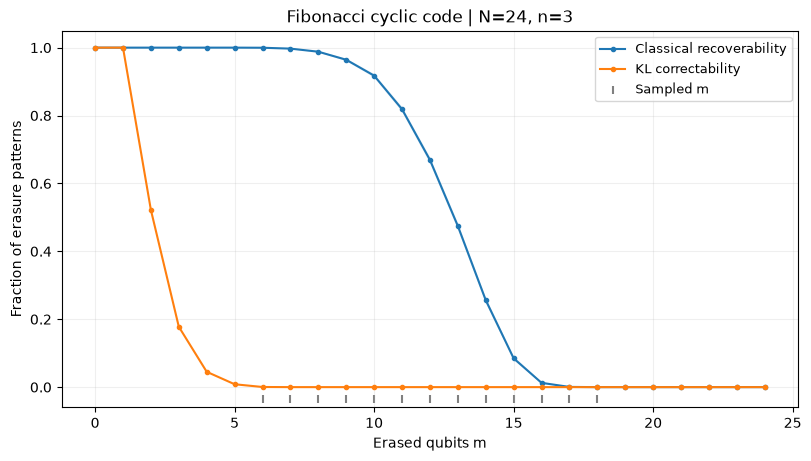

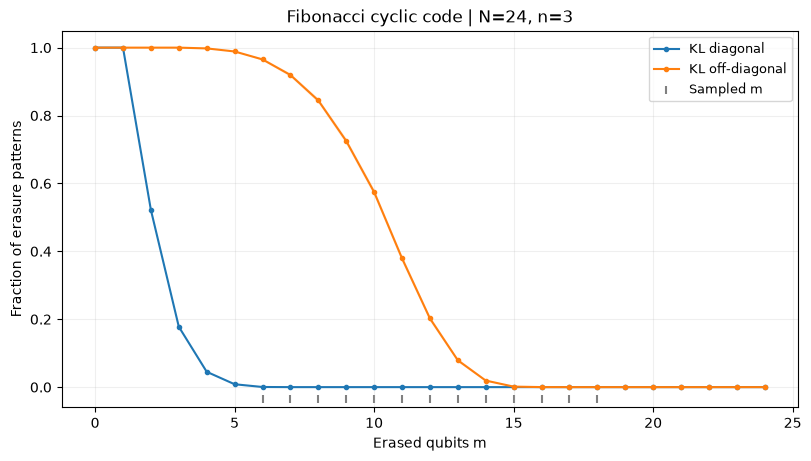

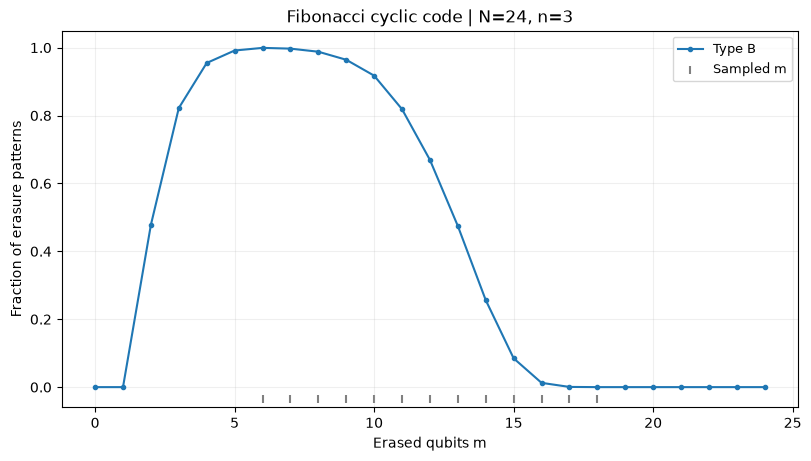

In [17]:
import matplotlib.pyplot as plt
figures = fib.plot_summary(summary, RESULTS_DIR)
plt.show()

## 20. Type B / Type C詳細解析
`inspect_erasure_pattern(E)` は元列・消失列・残存列、collision witness、KL diagonalが異なる具体的な行列要素を表示する。collisionがなくてもKL diagonalが破れるケースを説明できる。

Type Bはmの小さい順から最大3例（異なるmを優先）、Type Cも最大3例を表示する。Type Bの失敗理由の内訳は全数表で確認する。複数のmを合わせた表の件数は探索範囲の構成に依存するため、物理的な一つの訂正率として解釈しない。

In [18]:
def inspect_erasure_pattern(E):
    return model.inspect_erasure_pattern(E)

display(pd.crosstab(detail.comparison_type, detail.KL_failure_reason))
examples = {}
for kind in ("B", "C"):
    subset = detail[detail.comparison_type.eq(kind)]
    print(f"Type {kind}: {len(subset):,} evaluated trials")
    selected = subset.drop_duplicates("erasure_size").head(3)
    if len(selected) < min(3, len(subset)):
        selected = pd.concat([selected, subset]).drop_duplicates("erasure_positions").head(3)
    examples[kind] = []
    if selected.empty:
        print("今回の探索範囲では未検出。標本範囲や他のseed対での不存在は主張しません。")
    for E in selected.erasure_positions:
        examples[kind].append(inspect_erasure_pattern(E))
# 失敗機構の異なるBと、self collisionのあるDの実際のビット列も表示する。
for label, mask in [
    ("B_diagonal_and_offdiagonal", detail.comparison_type.eq("B") & detail.KL_failure_reason.eq("diagonal+offdiagonal")),
    ("D_self_collision", detail.comparison_type.eq("D")),
]:
    extra = detail[mask].head(1)
    examples[label] = [inspect_erasure_pattern(E) for E in extra.erasure_positions]
(RESULTS_DIR / "type_B_C_examples.json").write_text(json.dumps(examples, ensure_ascii=False, indent=2))

KL_failure_reason,diagonal,diagonal+offdiagonal,none
comparison_type,,,
A,0,0,1373
B,98129,27790,0
D,2553,111065,0


Type B: 125,919 evaluated trials
{
  "seed_length": 6,
  "k0": 3,
  "k1": 3,
  "adjacent_swap_valid": true,
  "seed_0": "000111",
  "seed_1": "010101",
  "inflation_n": 3,
  "N": 24,
  "orbit_size_0": 24,
  "orbit_size_1": 8,
  "erasure_size": 2,
  "erasure_positions": [
    0,
    7
  ],
  "recoverable_0": true,
  "recoverable_1": true,
  "recoverable_both": true,
  "self_collision_0": false,
  "self_collision_1": false,
  "cross_collision": false,
  "self_collision_count_0": 0,
  "self_collision_count_1": 0,
  "cross_collision_count": 0,
  "KL_diagonal": false,
  "KL_offdiagonal": true,
  "KL_correctable": false,
  "comparison_type": "B",
  "KL_failure_reason": "diagonal",
  "inflated_F0": "101101101101101011010110",
  "inflated_F1": "101101101011011010110110",
  "self_collision_examples_0": [],
  "self_collision_examples_1": [],
  "cross_collision_examples": [],
  "diagonal_mismatch_examples": [
    {
      "row_E": "00",
      "col_E": "00",
      "rho00": "1/12",
      "rho11": "0

17914

### Q1〜Q5の読み取り方と次の研究
- **Q1**：`baseline_reproduction.csv` の全行matchedを確認する。再現範囲は選択した既存pair・条件に限定する。
- **Q2**：BまたはCが1例でもあれば一致しない。標本での検出も存在の証拠だが、未検出は一般的な一致の証明ではない。
- **Q3**：Bの失敗理由表とinspectの有理数要素から、頻度不一致／交差項のどちらが原因かを特定する。
- **Q4**：recoverability失敗はself collisionありと同値。cross collisionありは本等振幅構成ではKL off-diagonal失敗と同値。self collisionの有無だけではKL diagonalの成否は決まらない。
- **Q5**：Bが見つかればrecoverabilityは十分条件ではない。Cが見つかれば必要条件でもない。Fibonacci族でCが見つからない場合、必要性は未解決として残す。一般の等振幅状態ではunit testの人工Type Cが反例になるが、族に関する結論と混同しない。

設計条件としては、各消失集合について正規化した自己部分トレースのカウント一致とcross collision排除の両方が必要十分である。recoverabilityだけをseed選択の指標にする前に、この差を調べる。

有限サイズスケーリング、中央領域W、相互情報量、相関関数、structure factor、seed最適化、HamiltonianはこのNotebookに含めない。次の `fibonacci_finite_size_scaling` では本計算の出典と判定を引き継げる。